## Пример разметки

Image: GC10_data/images/img_01_424799300_01133.jpg
Annotation: GC10_data/ann/img_01_424799300_01133.jpg.json


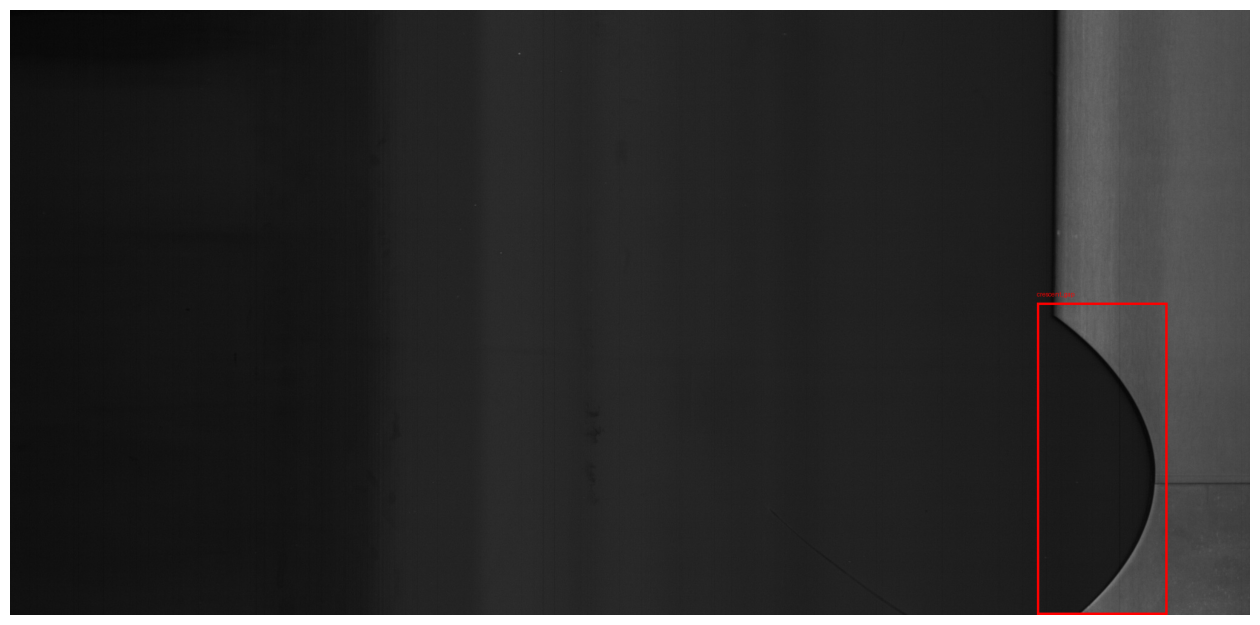

In [2]:
from pathlib import Path
import json
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt


image_path = Path(
    "GC10_data/images/img_01_424799300_01133.jpg"
)

annotation_path = Path(
    "GC10_data/ann/img_01_424799300_01133.jpg.json"
)


print("Image:", image_path)
print("Annotation:", annotation_path)


with open(annotation_path, "r", encoding="utf-8") as f:
    annotation = json.load(f)


image = Image.open(image_path).convert("RGB")

draw = ImageDraw.Draw(image)


for obj in annotation["objects"]:
    class_name = obj["classTitle"]

    (x1, y1), (x2, y2) = obj["points"]["exterior"]

    draw.rectangle(
        [x1, y1, x2, y2],
        outline="red",
        width=4
    )

    draw.text(
        (x1, max(0, y1 - 20)),
        class_name,
        fill="red"
    )


plt.figure(figsize=(16, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

## Baseline_yolo

In [3]:
from ultralytics import YOLO
from pathlib import Path

IMAGE_PATH =  "GC10_data/images/img_01_424799300_01133.jpg"
OUTPUT_PATH = "outputs/yolo/test_photo_img_01_424799300_01133.jpg"

Path("outputs/yolo").mkdir(parents=True, exist_ok=True)

model = YOLO("models/yolo11n.pt")

results = model.predict(
    source=IMAGE_PATH,
    conf=0.25,
    save=False
)

for result in results:

    result.save(filename=OUTPUT_PATH)

    for box in result.boxes:
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])
        class_name = result.names[cls_id]

        print(f"Class: {class_name}")
        print(f"Confidence: {conf:.4f}")

print(f"Saved to: {OUTPUT_PATH}")

/Users/alexanderfayda/Промышленная разработка на Python/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Disabling PyTorch because PyTorch >= 2.5 is required but found 2.2.2
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


image 1/1 /Users/alexanderfayda/Промышленная разработка на Python/GC10_data/images/img_01_424799300_01133.jpg: 320x640 (no detections), 163.3ms
Speed: 4.7ms preprocess, 163.3ms inference, 1.4ms postprocess per image at shape (1, 3, 320, 640)
Saved to: outputs/yolo/test_photo_img_01_424799300_01133.jpg


[W NNPACK.cpp:64] Could not initialize NNPACK! Reason: Unsupported hardware.


## Train

### Preparation of DF to YOLO

In [4]:
from pathlib import Path
import json
import random
import shutil


SOURCE_DIR = Path("GC10_data")

IMAGE_DIR = SOURCE_DIR / "images"
ANNOTATION_DIR = SOURCE_DIR / "ann"

YOLO_DIR = Path("GC10_yolo")


for split in ["train", "val", "test"]:
    (YOLO_DIR / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (YOLO_DIR / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

In [5]:
annotation_files = list(
    ANNOTATION_DIR.glob("*.json")
)

print("Annotations:", len(annotation_files))


class_names = set()

for annotation_path in annotation_files:

    with open(
        annotation_path,
        "r",
        encoding="utf-8"
    ) as f:

        annotation = json.load(f)

    for obj in annotation.get("objects", []):
        class_names.add(
            obj["classTitle"]
        )


class_names = sorted(class_names)

class_to_id = {
    class_name: i
    for i, class_name in enumerate(class_names)
}


print("Classes:")

for class_name, class_id in class_to_id.items():
    print(class_id, class_name)

Annotations: 2300
Classes:
0 crease
1 crescent_gap
2 inclusion
3 oil_spot
4 punching_hole
5 rolled_pit
6 silk_spot
7 waist folding
8 water_spot
9 welding_line


In [6]:
samples = []

for annotation_path in annotation_files:

    # например:
    # img_01_424799300_01133.jpg.json
    #
    # превращаем в:
    # img_01_424799300_01133.jpg

    image_name = annotation_path.name[:-5]

    image_path = IMAGE_DIR / image_name

    if image_path.exists():
        samples.append(
            (image_path, annotation_path)
        )


print("Samples:", len(samples))

Samples: 2294


In [7]:
random.seed(42)
random.shuffle(samples)

In [8]:
n = len(samples)

train_end = int(n * 0.70)
val_end = int(n * 0.85)


train_samples = samples[:train_end]

val_samples = samples[
    train_end:val_end
]

test_samples = samples[
    val_end:
]


print("Train:", len(train_samples))
print("Val:", len(val_samples))
print("Test:", len(test_samples))

Train: 1605
Val: 344
Test: 345


In [9]:
def convert_sample(
    image_path,
    annotation_path,
    split
):

    with open(
        annotation_path,
        "r",
        encoding="utf-8"
    ) as f:

        annotation = json.load(f)


    image_width = annotation["size"]["width"]
    image_height = annotation["size"]["height"]


    lines = []


    for obj in annotation.get("objects", []):

        class_name = obj["classTitle"]

        class_id = class_to_id[class_name]


        points = obj["points"]["exterior"]

        (x1, y1), (x2, y2) = points


        x_min = min(x1, x2)
        x_max = max(x1, x2)

        y_min = min(y1, y2)
        y_max = max(y1, y2)


        # centre
        x_center = (x_min + x_max) / 2
        y_center = (y_min + y_max) / 2


        # dimensions
        box_width = x_max - x_min
        box_height = y_max - y_min


        # normalize
        x_center /= image_width
        y_center /= image_height

        box_width /= image_width
        box_height /= image_height


        line = (
            f"{class_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{box_width:.6f} "
            f"{box_height:.6f}"
        )

        lines.append(line)


    # copy image

    output_image = (
        YOLO_DIR /
        "images" /
        split /
        image_path.name
    )

    shutil.copy2(
        image_path,
        output_image
    )


    # create txt

    output_label = (
        YOLO_DIR /
        "labels" /
        split /
        f"{image_path.stem}.txt"
    )

    with open(
        output_label,
        "w",
        encoding="utf-8"
    ) as f:

        f.write("\n".join(lines))

In [10]:
for image_path, annotation_path in train_samples:
    convert_sample(
        image_path,
        annotation_path,
        "train"
    )


for image_path, annotation_path in val_samples:
    convert_sample(
        image_path,
        annotation_path,
        "val"
    )


for image_path, annotation_path in test_samples:
    convert_sample(
        image_path,
        annotation_path,
        "test"
    )

In [11]:
print(
    "Train:",
    len(list(
        (YOLO_DIR / "images/train").glob("*.jpg")
    ))
)

print(
    "Val:",
    len(list(
        (YOLO_DIR / "images/val").glob("*.jpg")
    ))
)

print(
    "Test:",
    len(list(
        (YOLO_DIR / "images/test").glob("*.jpg")
    ))
)

Train: 1605
Val: 344
Test: 345


In [12]:
yaml_path = YOLO_DIR / "data.yaml"


with open(
    yaml_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        f"path: {YOLO_DIR.resolve()}\n"
    )

    f.write(
        "train: images/train\n"
    )

    f.write(
        "val: images/val\n"
    )

    f.write(
        "test: images/test\n\n"
    )

    f.write(
        "names:\n"
    )

    for i, class_name in enumerate(class_names):

        f.write(
            f"  {i}: {class_name}\n"
        )


print(
    yaml_path.read_text()
)

path: /Users/alexanderfayda/Промышленная разработка на Python/GC10_yolo
train: images/train
val: images/val
test: images/test

names:
  0: crease
  1: crescent_gap
  2: inclusion
  3: oil_spot
  4: punching_hole
  5: rolled_pit
  6: silk_spot
  7: waist folding
  8: water_spot
  9: welding_line



### Train YOLO11n

In [15]:
from ultralytics import YOLO


model = YOLO(
    "models/yolo11n.pt"
)


results = model.train(
    data="GC10_yolo/data.yaml",

    epochs=1,

    imgsz=640,

    batch=8,

    project="outputs/yolo_train",

    name="baseline_v1",

    seed=42,

    exist_ok=True
)

New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.11.15 torch-2.2.2 CPU (Apple M4)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=GC10_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=models/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_

In [17]:
best_model = YOLO(
    "runs/detect/outputs/yolo_train/baseline_v1/weights/best.pt"
)

In [18]:
metrics = best_model.val(
    data="GC10_yolo/data.yaml",
    split="test"
)

Ultralytics 8.4.173 🚀 Python-3.11.15 torch-2.2.2 CPU (Apple M4)
YOLO11n summary (fused): 100 layers, 2,584,102 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 728.7±155.6 MB/s, size: 369.0 KB)
val: Scanning /Users/alexanderfayda/Промышленная разработка на Python/GC10_yolo/labels/test... 345 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 345/345 2.8Kit/s 0.1s<0.1s
val: New cache created: /Users/alexanderfayda/Промышленная разработка на Python/GC10_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 1.2it/s 17.7s0.9s
                   all        345        539      0.462      0.219      0.148     0.0577
                crease          4          7          1          0          0          0
          crescent_gap         49         49       0.28      0.246      0.301      0.137
             inclusion         33         52      0.247      0.115      0.069     0.

In [19]:
print(
    "mAP@0.50:",
    metrics.box.map50
)

print(
    "mAP@0.50:0.95:",
    metrics.box.map
)

print(
    "Precision:",
    metrics.box.mp
)

print(
    "Recall:",
    metrics.box.mr
)

mAP@0.50: 0.14764891116292042
mAP@0.50:0.95: 0.057671335488368704
Precision: 0.46160649388543434
Recall: 0.21854117409331913


### Prediction on untrained picture

In [63]:
from pathlib import Path


test_image = next(
    Path(
        "GC10_yolo/images/test"
    ).glob("*.jpg")
)


print(
    "Test image:",
    test_image
)

Test image: GC10_yolo/images/test/img_06_425616500_00769.jpg


In [60]:
results = best_model.predict(
    source=str(test_image),

    conf=0.25,

    save=False
)


image 1/1 /Users/alexanderfayda/Промышленная разработка на Python/GC10_yolo/images/test/img_06_425616500_00769.jpg: 320x640 1 oil_spot, 97.3ms
Speed: 3.6ms preprocess, 97.3ms inference, 18.3ms postprocess per image at shape (1, 3, 320, 640)


In [61]:
OUTPUT_PATH = (
    "outputs/yolo_prediction/"
    + test_image.name
)


Path(
    "outputs/yolo_prediction"
).mkdir(
    parents=True,
    exist_ok=True
)


for result in results:

    result.save(
        filename=OUTPUT_PATH
    )

    print(
        "Number of detections:",
        len(result.boxes)
    )


    for box in result.boxes:

        cls_id = int(
            box.cls[0]
        )

        confidence = float(
            box.conf[0]
        )

        class_name = (
            result.names[cls_id]
        )


        print(
            f"Class: {class_name}"
        )

        print(
            f"Confidence: {confidence:.4f}"
        )


print(
    f"Saved to: {OUTPUT_PATH}"
)

Number of detections: 1
Class: oil_spot
Confidence: 0.2899
Saved to: outputs/yolo_prediction/img_06_425616500_00769.jpg


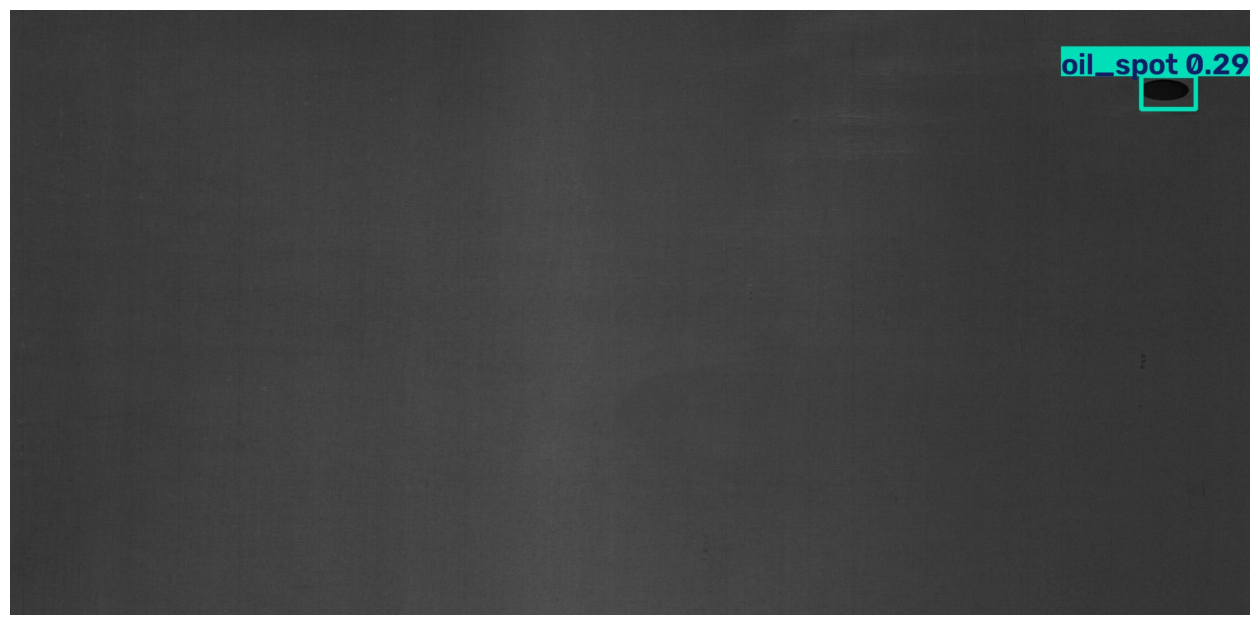

In [62]:
from PIL import Image
import matplotlib.pyplot as plt


prediction_image = Image.open(
    OUTPUT_PATH
)


plt.figure(
    figsize=(16, 8)
)

plt.imshow(
    prediction_image
)

plt.axis("off")

plt.show()